# 02 - Exploratory Data Analysis (EDA)
**Team 05 - The Budget Illusion | CS215: Data Analysis and Interpretation**

Data: `CleanedDataSet.csv` (1,698 films).
What we do: summary statistics -> histograms -> compare revenue across franchise / remake / release period -> count recurring lead stars and directors -> write observations.
Tools: pandas, matplotlib, scipy.stats.

In [1]:
import math
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

plt.style.use("seaborn-v0_8-whitegrid")

## 1. Load the data

The cleaned file has the encoded variables (flags, genre dummies, `ROI`, `Movie_Scale`), but no `Lead Star`,
`Director` or `Release Period` text. We join those back from `DataSet.csv` using the movie title (every title
matches exactly once).

In [2]:
df = pd.read_csv("CleanedDataSet.csv").rename(
    columns={"Budget(INR)": "Budget", "Revenue(INR)": "Revenue"})

source = pd.read_csv("DataSet.csv")
df = df.merge(source[["Movie Name", "Lead Star", "Director"]],
              on="Movie Name", how="left")

print("rows:", len(df), " columns:", df.shape[1])
df.head(3)

rows: 1698  columns: 28


,Movie Name,Whether Remake,Whether Franchise,Holiday_Release,Genre_adult,Genre_animation,Genre_comedy,Genre_documentary,Genre_drama,Genre_fantasy,Genre_horror,Genre_love_story,Genre_masala,Genre_mythological,Genre_rom_com,Genre_suspense,Genre_thriller,New Actor,New Director,New Music Director,Budget,Revenue,Number of Screens,Revenue Per Screen,Movie_Scale,ROI,Lead Star,Director
0,Qaidi Band,False,False,True,False,False,False,False,True,False,False,False,False,False,False,False,False,True,False,False,210000000,4500000,800,5625.0,7.803,0.021429,Aadar Jain,Habib Faisal
1,Chaatwali,False,False,True,True,False,False,False,False,False,False,False,False,False,False,False,False,True,True,True,1000000,1075000,1,1075000.0,1.576,1.075000,Aadil Khan,Aadil Khan
2,Shuttlecock Boys,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,True,True,True,5000000,170000,10,17000.0,3.393,0.034000,Aakar Kaushik,Hemant Gaba


## 2. Summary statistics for Budget, Revenue and ROI

All three are right-skewed (a few blockbusters pull the mean far above the median), so the median is the more
honest summary of a typical film.

In [3]:
print(df[['Movie Name', 'Lead Star', 'Director']].describe().T,f"\n{'~'*50}")
print(df.select_dtypes(include=['bool']).describe().T,f"\n{'~'*50}")
with pd.option_context('display.float_format', '{:,.3f}'.format):
    print(df.select_dtypes(include=['int64', 'float64']).describe().T,f"\n{'~'*50}")

           count unique              top freq
Movie Name  1698   1698       Qaidi Band    1
Lead Star   1698    761     Akshay Kumar   48
Director    1698   1045  Ram Gopal Verma   18 
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
                   count unique    top  freq
Whether Remake      1698      2  False  1588
Whether Franchise   1698      2  False  1618
Holiday_Release     1698      2  False  1052
Genre_adult         1698      2  False  1622
Genre_animation     1698      2  False  1693
Genre_comedy        1698      2  False  1416
Genre_documentary   1698      2  False  1697
Genre_drama         1698      2  False  1056
Genre_fantasy       1698      2  False  1685
Genre_horror        1698      2  False  1644
Genre_love_story    1698      2  False  1567
Genre_masala        1698      2  False  1686
Genre_mythological  1698      2  False  1684
Genre_rom_com       1698      2  False  1601
Genre_suspense      1698      2  False  1669
Genre_thriller      1698      2  False  1482

In [4]:
print("Films that lost money (ROI < 1):          %.1f%%" % ((df["ROI"] < 1).mean() * 100))
print("Films with ROI below 0.5:                %.1f%%" % ((df["ROI"] < 0.5).mean() * 100))
print("Films grossing under 1 crore:            %.1f%%" % ((df["Revenue"] < 1e7).mean() * 100))
print("Films with budget above 10 crore:        %.1f%%" % ((df["Budget"] > 1e8).mean() * 100))

Films that lost money (ROI < 1):          72.1%
Films with ROI below 0.5:                57.3%
Films grossing under 1 crore:            47.7%
Films with budget above 10 crore:        35.9%


## 3. Histograms

First row: the variables as they are. Second row: the same data on a log10 scale, because on the raw scale nearly
every film is squeezed into the first bin.

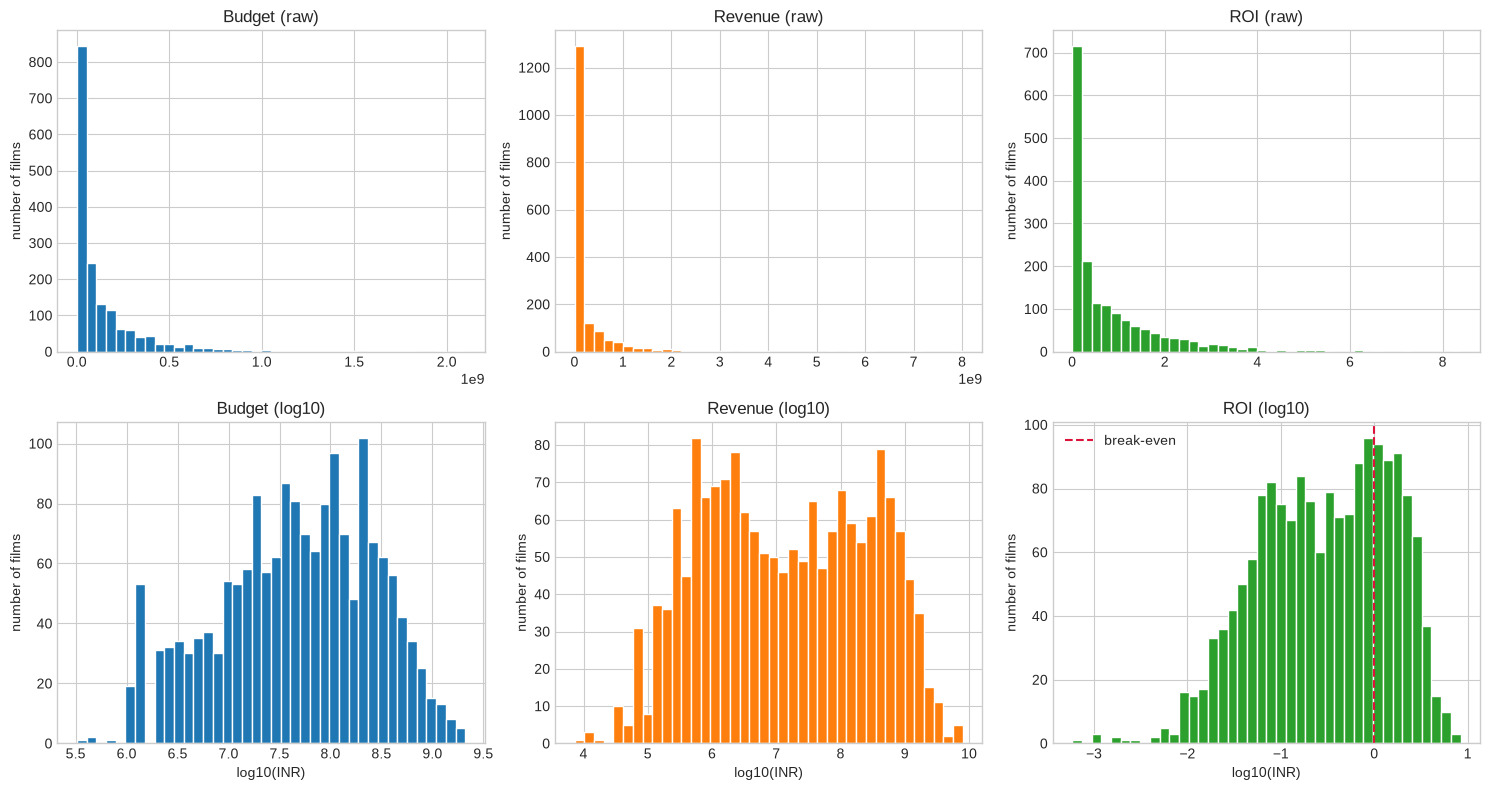

In [5]:
vars_of_interest = ["Budget", "Revenue", "ROI"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for col, (variable, colour) in enumerate(zip(vars_of_interest, ["tab:blue", "tab:orange", "tab:green"])):
    ax = axes[0][col]
    ax.hist(df[variable], bins=40, color=colour, edgecolor="white")
    ax.set_title(f"{variable} (raw)")
    ax.set_ylabel("number of films")

    ax = axes[1][col]
    logged = df[variable].apply(math.log10)
    ax.hist(logged, bins=40, color=colour, edgecolor="white")
    if variable == "ROI":
        ax.axvline(0, color="crimson", linestyle="--", label="break-even")
        ax.legend()
    ax.set_title(f"{variable} (log10)")
    ax.set_xlabel("log10(INR)")
    ax.set_ylabel("number of films")

plt.tight_layout()
plt.savefig("histograms/economy_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

## 4. Franchise vs non-franchise films

`Whether Franchise` is 1 for franchise films and 0 for the rest.

In [6]:
def compare_groups(frame, column, label_1, label_0, value="Revenue"):
    # Print a small summary table for two groups and a t-test on the group means.
    table = frame.groupby(column)[value].agg(["count", "mean", "median", "std"])
    print(table.to_string(float_format=lambda v: f"{v:,.0f}"))

    group_1 = frame.loc[frame[column] == label_1, value]
    group_0 = frame.loc[frame[column] == label_0, value]
    t_stat, p_value = stats.ttest_ind(group_1, group_0, equal_var=False)
    print(f"\n{label_1} vs {label_0}: median {group_1.median():,.0f} vs {group_0.median():,.0f}"
          f"  ({group_1.median() / group_0.median():.1f}x),  Welch t-test p = {p_value:.2g}")

    # Budget and screens are shown too, so we can see how much of the gap is scale.
    print("\nMedian budget and screens by group:")
    print(frame.groupby(column)[["Budget", "Number of Screens", "ROI"]].median().to_string(float_format=lambda v: f"{v:,.2f}"))


print("=== Revenue by franchise status (INR) ===")
compare_groups(df, "Whether Franchise", True, False)

=== Revenue by franchise status (INR) ===
                   count        mean      median           std
Whether Franchise                                             
False               1618 200,397,863  10,050,000   530,057,271
True                  80 994,388,269 577,717,500 1,312,939,406

True vs False: median 577,717,500 vs 10,050,000  (57.5x),  Welch t-test p = 7e-07

Median budget and screens by group:
                          Budget  Number of Screens  ROI
Whether Franchise                                       
False              50,000,000.00             175.00 0.30
True              300,000,000.00           1,500.00 1.73


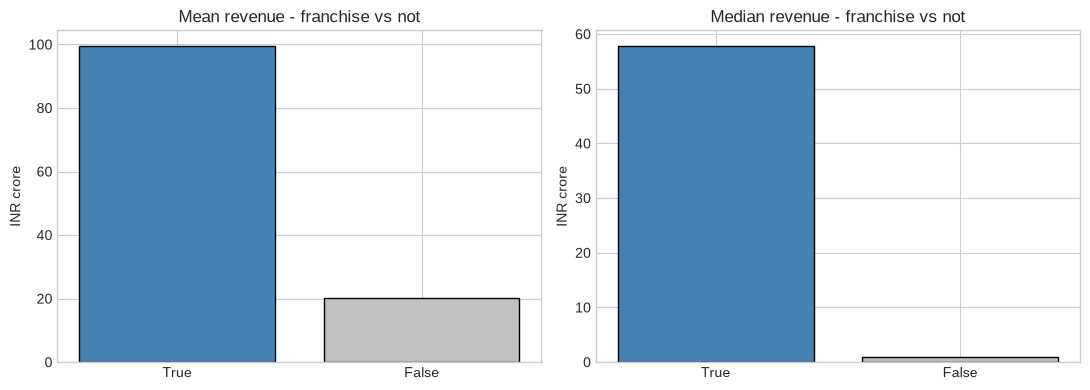

In [7]:
def bar_comparison(frame, column, labels, value="Revenue", title=""):
    means = (frame.groupby(column)[value].mean() / 1e7).reindex(labels)
    medians = (frame.groupby(column)[value].median() / 1e7).reindex(labels)

    str_labels = [str(label) for label in labels]

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].bar(str_labels, means, color=["steelblue", "silver"], edgecolor="black")
    axes[0].set_ylabel("INR crore")
    axes[0].set_title(f"Mean revenue - {title}")

    axes[1].bar(str_labels, medians, color=["steelblue", "silver"], edgecolor="black")
    axes[1].set_ylabel("INR crore")
    axes[1].set_title(f"Median revenue - {title}")

    plt.tight_layout()
    plt.savefig(f"histograms/{title.replace(' ', '_')}.png", dpi=300, bbox_inches="tight")
    plt.show()

bar_comparison(df, "Whether Franchise", [True, False], title="franchise vs not")

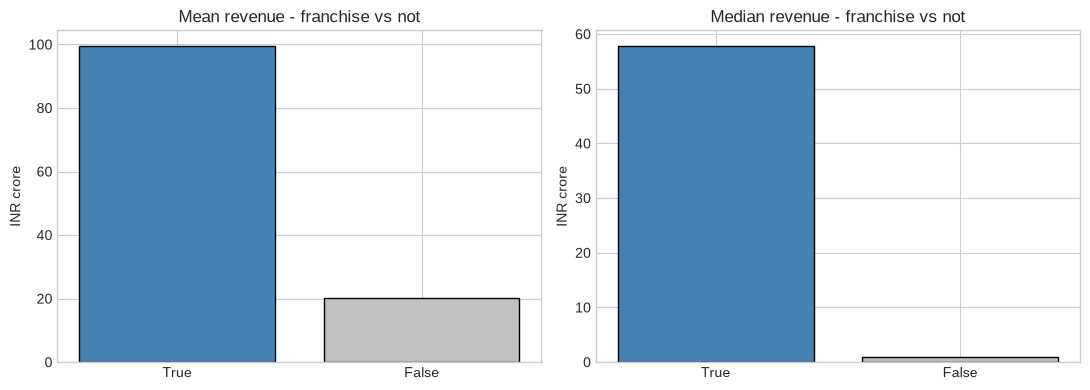

In [8]:
bar_comparison(df, "Whether Franchise", [True, False], title="franchise vs not")

## 5. Remake vs non-remake films

In [9]:
print("=== Revenue by remake status (INR) ===")
compare_groups(df, "Whether Remake", 1, 0)

=== Revenue by remake status (INR) ===
                count        mean      median         std
Whether Remake                                           
False            1588 210,026,665   8,650,000 600,207,974
True              110 638,840,543 388,083,750 663,042,946

1 vs 0: median 388,083,750 vs 8,650,000  (44.9x),  Welch t-test p = 1.1e-09

Median budget and screens by group:
                       Budget  Number of Screens  ROI
Whether Remake                                       
False           45,000,000.00             175.00 0.28
True           270,000,000.00           1,200.00 1.41


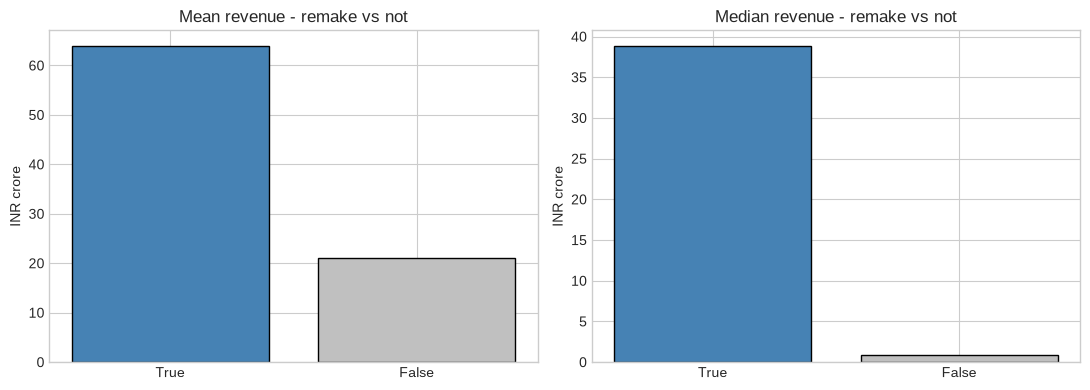

In [10]:
bar_comparison(df, "Whether Remake", [True, False], title="remake vs not")

## 6. Revenue across release periods

In [11]:
print("=== Revenue by release period (INR) ===")
compare_groups(df, "Holiday_Release", True, False)

=== Revenue by release period (INR) ===
                 count        mean     median         std
Holiday_Release                                          
False             1052 152,092,181  9,200,000 321,948,877
True               646 377,389,830 22,925,000 888,600,809

True vs False: median 22,925,000 vs 9,200,000  (2.5x),  Welch t-test p = 9.4e-10

Median budget and screens by group:
                       Budget  Number of Screens  ROI
Holiday_Release                                      
False           47,500,000.00             175.00 0.28
True            75,000,000.00             287.50 0.44


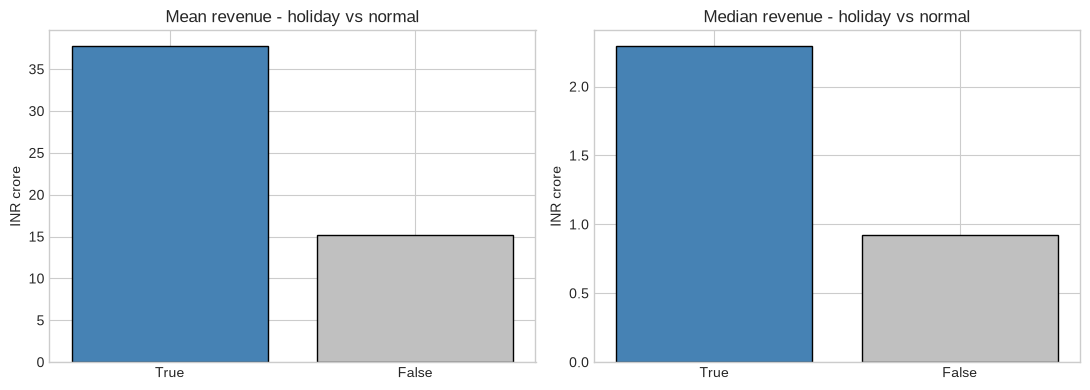

In [12]:
bar_comparison(df, "Holiday_Release", [True, False], title="holiday vs normal")

## 7. Recurring lead stars and directors

In [13]:
star_counts = df["Lead Star"].value_counts()
director_counts = df["Director"].value_counts()

print("=== Top 15 lead stars by number of films ===")
print(star_counts.head(15).to_string())
print("\ndistinct lead stars:", df["Lead Star"].nunique())
print("share of films with a top-10 star: %.1f%%" % (star_counts.head(10).sum() / len(df) * 100))
print("films whose lead star appears only once: %d (%.1f%%)" % ((star_counts == 1).sum(), (star_counts == 1).sum() / len(df) * 100))

print("\n=== Top 15 directors by number of films ===")
print(director_counts.head(15).to_string())
print("\ndistinct directors:", df["Director"].nunique())
print("share of films with a top-10 director: %.1f%%" % (director_counts.head(10).sum() / len(df) * 100))
print("films whose director appears only once: %d (%.1f%%)" % ((director_counts == 1).sum(), (director_counts == 1).sum() / len(df) * 100))

=== Top 15 lead stars by number of films ===
Lead Star
Akshay Kumar         48
Ajay Devgn           35
Emraan Hashmi        27
Salman Khan          26
Amitabh Bachchan     20
Saif Ali Khan        19
Sanjay Dutt          18
Shahid Kapoor        18
John Abraham         17
Ranbir Kapoor        16
Shahrukh Khan        16
Jackie Shroff        15
Jimmy Shergill       15
Sunny Deol           15
Abhishek Bachchan    13

distinct lead stars: 761
share of films with a top-10 star: 14.4%
films whose lead star appears only once: 540 (31.8%)

=== Top 15 directors by number of films ===
Director
Ram Gopal Verma      18
Vikram Bhatt         16
Priyadarshan         16
Suresh Jain          15
Mohit Suri           11
Rohit Shetty         11
Anurag Kashyap       10
Madhur Bhandarkar     9
Anees Bazmee          9
David Dhawan          8
Anant Mahadevan       8
Kanti Shah            8
Imtiaz Ali            7
Abbas - Mustan        7
Vishal Bhardwaj       7

distinct directors: 1045
share of films with a top

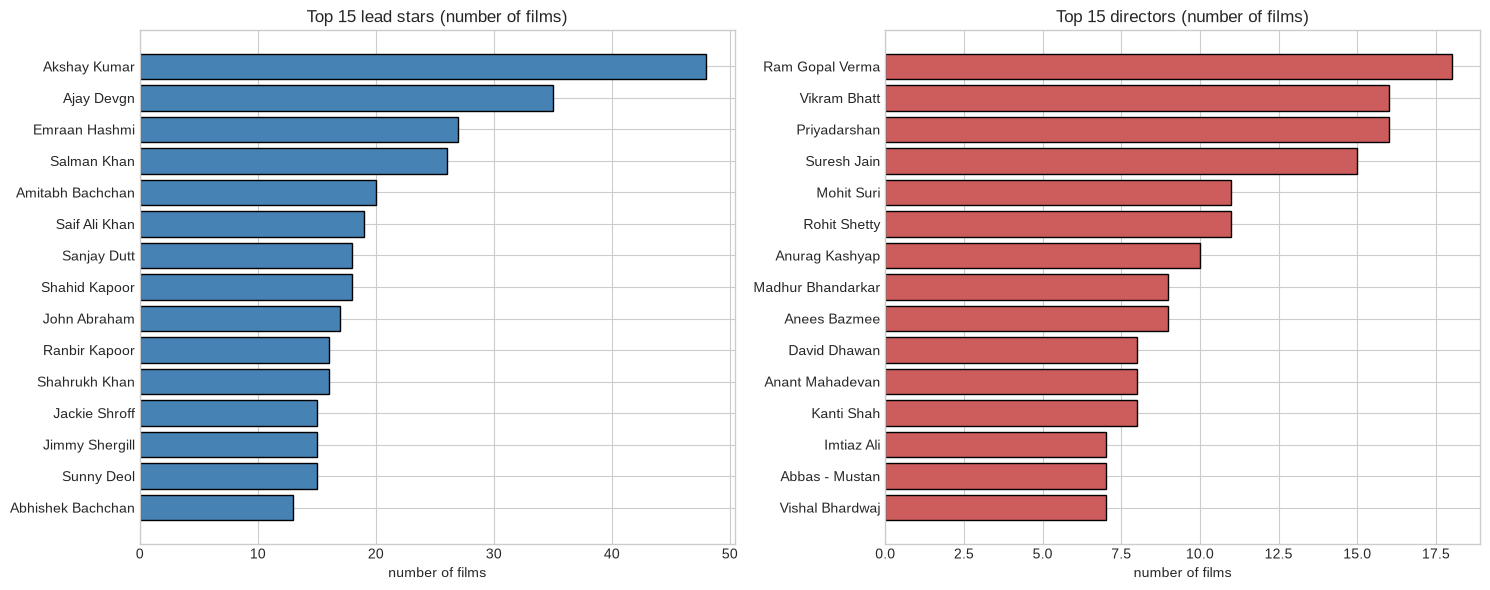

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

top_stars = star_counts.head(15).iloc[::-1]
axes[0].barh(top_stars.index, top_stars.values, color="steelblue", edgecolor="black")
axes[0].set_title("Top 15 lead stars (number of films)")
axes[0].set_xlabel("number of films")

top_directors = director_counts.head(15).iloc[::-1]
axes[1].barh(top_directors.index, top_directors.values, color="indianred", edgecolor="black")
axes[1].set_title("Top 15 directors (number of films)")
axes[1].set_xlabel("number of films")

plt.tight_layout()
plt.savefig("histograms/top_stars_directors.png", dpi=300, bbox_inches="tight")
plt.show()

In [15]:
# Do the busiest names also earn more?
top_stars = star_counts.head(10).index
top_directors = director_counts.head(10).index

for label, names in [("top-10 lead stars", top_stars), ("top-10 directors", top_directors)]:
    with_name = df.loc[df["Lead Star"].isin(names) if "star" in label else df["Director"].isin(names), "Revenue"]
    without_name = df.loc[~df["Lead Star"].isin(names) if "star" in label else ~df["Director"].isin(names), "Revenue"]
    print(f"{label}: median {with_name.median() / 1e7:,.2f} crore (n={len(with_name)}) vs "
          f"{without_name.median() / 1e7:,.2f} crore (n={len(without_name)})")

top-10 lead stars: median 46.28 crore (n=244) vs 0.55 crore (n=1454)
top-10 directors: median 20.49 crore (n=123) vs 0.96 crore (n=1575)


## 8. Observations

**1. The typical film is far weaker than the average suggests.**
Mean budget is Rs 18.0 crore but the median is Rs 9.0 crore; mean revenue is Rs 30.0 crore but the median is only
Rs 4.1 crore (revenue skew = 4.77). **65.1% of the films lost money** (ROI below 1) and 34.2% grossed under
Rs 1 crore, so a handful of blockbusters are carrying the averages.

**2. Franchise and remake films earn much more, but they are also much bigger films.**
Franchise films (n = 78) have a median revenue of Rs 57.8 crore against Rs 3.4 crore for the rest (t-test p = 6.9e-07),
and remakes (n = 126) Rs 35.9 crore against Rs 3.1 crore (p = 3.8e-07). Part of that gap is scale: the median
franchise budget is Rs 29 crore and the median remake budget Rs 24 crore, versus Rs 8 crore for everything else.
Their ROI is higher too (franchise median 1.93 vs 0.43, remake 1.39 vs 0.39), so the gap is not purely mechanical,
but absolute revenue differences between these groups and the rest are inflated by size.

**3. Holiday releases earn more without being dramatically bigger films.**
Holiday films (n = 514) have a median revenue of Rs 7.9 crore versus Rs 3.3 crore for normal releases
(p = 1.9e-09). Their median budget is Rs 11.0 crore against Rs 7.8 crore and their median ROI is 0.71 against 0.40,
so the revenue gap (2.4x) is larger than the budget gap (1.4x) - release timing looks like it pays beyond scale.
This is still an association, not a cause.

**4. The money is concentrated in a small set of recurring names.**
The 1,317 films cover 501 different lead stars and 767 different directors. The top 10 stars appear on only 18.3%
of the films and the top 10 directors on 8.8%, yet films with a top-10 star earn a median of Rs 46.3 crore versus
Rs 1.9 crore for the rest, and films with a top-10 director Rs 21.4 crore versus Rs 3.2 crore. Akshay Kumar
(48 films), Ajay Devgn (34) and Emraan Hashmi (27) lead the star counts; Ram Gopal Verma (18), Vikram Bhatt (16)
and Priyadarshan (16) lead the director counts. These names are also given bigger budgets and screens, so
recurrence marks the successful films rather than explaining them.

**One caveat for the next stage.** The release-period flag inside `CleanedDataSet_final.csv` disagrees with the
source label on 108 of 1,317 rows (8.2%), and the dataset has no release year, so the rupee amounts are nominal and
not inflation adjusted.